In [ ]:
#biblioteki
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras import layers, Model
from torch.utils.data import DataLoader, TensorDataset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [ ]:
#wczytwanie danych
base_dir = kagglehub.dataset_download("mahdihabibi/segmented-peripheral-blood-cells-using-opencv")
image_dir = os.path.join(base_dir, "original_images/original_images")
mask_dir = os.path.join(base_dir, "binary_masks/binary_masks")

In [ ]:
cell_type_folder_mask = []
cell_type_folder_original = []
images = []
masks = []

for cell_type in os.listdir(mask_dir):
    cell_type_folder_mask.append(os.path.join(mask_dir, cell_type))
    cell_type_folder_original.append(os.path.join(image_dir, cell_type))

print(cell_type_folder_mask)
print(cell_type_folder_original)


for folder1, folder2 in zip(cell_type_folder_mask, cell_type_folder_original):
    print(f"Przetwarzanie folderu: {folder1}")

    #iteracja po plikach w folderze maski (folder1)
    for img_name in os.listdir(folder1):
        if img_name.endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            image_file_path = os.path.join(folder1, img_name)
            mask = Image.open(image_file_path).resize((368, 368))
            masks.append(mask)  # Dodanie maski binarnej do listy

    print(f"Przetwarzanie folderu: {folder2}")

    #iteracja po plikach w folderze obrazów oryginalnych (folder2)
    for img_name in os.listdir(folder2):
        if img_name.endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            image_file_path = os.path.join(folder2, img_name)
            image = Image.open(image_file_path).resize((368, 368))
            images.append(image)

#sprawdzenie liczby wczytanych obrazów i masek
print(f"Liczba wczytanych obrazów: {len(images)}")
print(f"Liczba wczytanych masek: {len(masks)}")

['/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/lymphocyte', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/eosinophil', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/erythroblast', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/neutrophil', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/basophil', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/ig', '/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/binary_masks/binary_masks/platelet', '/root/.cache/kagglehu

In [ ]:
masks_normalized = np.array(masks)/255

#podział na zbiory treningowy, walidacyjny i testowy
val_split, test_split = 0.2, 0.1
train_images, temp_images, train_masks, temp_masks = train_test_split(
    images, masks_normalized, test_size=val_split + test_split, random_state=42
)
val_images, test_images, val_masks, test_masks = train_test_split(
    temp_images, temp_masks, test_size=test_split / (val_split + test_split), random_state=42
)

train_images = np.array([np.array(img) for img in train_images]).astype(np.float32) / 255.0
train_masks = np.array([np.array(mask) for mask in train_masks]).astype(np.float32)
val_images = np.array([np.array(img) for img in val_images]).astype(np.float32) / 255.0
val_masks = np.array([np.array(mask) for mask in val_masks]).astype(np.float32)

# Dodanie wymiaru kanału dla masek
train_masks = np.expand_dims(train_masks, axis=1)  # Maski: (N, 1, H, W)
val_masks = np.expand_dims(val_masks, axis=1)

# Transpozycja obrazów RGB do formatu (N, C, H, W)
train_images = np.transpose(train_images, (0, 3, 1, 2))  # Obrazy: (N, 3, H, W)
val_images = np.transpose(val_images, (0, 3, 1, 2))

# Konwersja na tensory
train_images = torch.tensor(train_images, dtype=torch.float32)
train_masks = torch.tensor(train_masks, dtype=torch.float32)
val_images = torch.tensor(val_images, dtype=torch.float32)
val_masks = torch.tensor(val_masks, dtype=torch.float32)
train_dataset = torch.utils.data.TensorDataset(train_images, train_masks)
val_dataset = torch.utils.data.TensorDataset(val_images, val_masks)

# Tworzenie DataLoaderów
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

In [ ]:
# Definicja modelu UNet
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # Enkoder
        self.enc_conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.enc_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.enc_conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # Dekoder
        self.dec_conv1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec_conv2 = nn.ConvTranspose2d(64, 16, kernel_size=2, stride=2)
        self.dec_conv3 = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        x1 = F.relu(self.enc_conv1(x))
        x1_pooled = self.pool(x1)

        x2 = F.relu(self.enc_conv2(x1_pooled))
        x2_pooled = self.pool(x2)

        x3 = F.relu(self.enc_conv3(x2_pooled))

        x4 = F.relu(self.dec_conv1(x3))
        x4 = torch.cat([x4, x2], dim=1)

        x5 = F.relu(self.dec_conv2(x4))
        x5 = torch.cat([x5, x1], dim=1)

        output = torch.sigmoid(self.dec_conv3(x5))

        return output

# ======== Metryki ========
def iou_score(y_pred, y_true, epsilon=1e-6):
    """Obliczanie Intersection over Union (IoU)"""
    intersection = torch.sum(y_pred * y_true, dim=(1, 2, 3))
    union = torch.sum(y_pred, dim=(1, 2, 3)) + torch.sum(y_true, dim=(1, 2, 3)) - intersection
    iou = (intersection + epsilon) / (union + epsilon)
    return iou.mean()

def f1_score(y_pred, y_true, epsilon=1e-6):
    """Obliczanie F1 score"""
    tp = torch.sum(y_pred * y_true, dim=(1, 2, 3))  # True positives
    fp = torch.sum(y_pred * (1 - y_true), dim=(1, 2, 3))  # False positives
    fn = torch.sum((1 - y_pred) * y_true, dim=(1, 2, 3))  # False negatives
    precision = tp / (tp + fp + epsilon)  # Precision
    recall = tp / (tp + fn + epsilon)  # Recall
    f1 = (2 * precision * recall + epsilon) / (precision + recall + epsilon)  # F1-score
    return f1.mean()

In [ ]:
# ======== Przygotowanie modelu ========
model_u = UNet()
criterion = nn.BCELoss()  # Lepsza stabilność
optimizer = optim.Adam(model_u.parameters(), lr=0.001)  # Mniejszy współczynnik uczenia
train_losses = []
val_losses = []
train_f1_scores = []
val_f1_scores = []
train_iou_scores = []
val_iou_scores = []
# ======== Trenowanie modelu ========
num_epochs = 15  # Zwiększenie liczby epok dla lepszej konwergencji

for epoch in range(num_epochs):
    model_u.train()
    train_loss, train_f1, train_iou = 0.0, 0.0, 0.0
    for inputs, labels in train_loader:
        outputs = model_u(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

        # Metrics calculation
        train_f1 += f1_score(outputs, labels)
        train_iou += iou_score(outputs, labels)

    train_loss /= len(train_loader)
    train_f1 /= len(train_loader)
    train_iou /= len(train_loader)

    train_losses.append(train_loss)
    train_f1_scores.append(train_f1)
    train_iou_scores.append(train_iou)

    model_u.eval()
    val_loss, val_f1, val_iou = 0.0, 0.0, 0.0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model_u(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            val_f1 += f1_score(outputs, labels)
            val_iou += iou_score(outputs, labels)

    val_loss /= len(val_loader)
    val_f1 /= len(val_loader)
    val_iou /= len(val_loader)

    val_losses.append(val_loss)
    val_f1_scores.append(val_f1)
    val_iou_scores.append(val_iou)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train F1: {train_f1:.4f}, Train IoU: {train_iou:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val F1: {val_f1:.4f}, Val IoU: {val_iou:.4f}")

torch.save(model_u, "model_v2_1.pth")

Epoch 1/15
Train Loss: 0.3339, Train F1: 0.1700, Train IoU: 0.0938
Val Loss: 0.2218, Val F1: 0.2022, Val IoU: 0.1136
Epoch 2/15
Train Loss: 0.1506, Train F1: 0.4744, Train IoU: 0.3411
Val Loss: 0.0862, Val F1: 0.7360, Val IoU: 0.5990
Epoch 3/15
Train Loss: 0.0831, Train F1: 0.7756, Train IoU: 0.6491
Val Loss: 0.0744, Val F1: 0.8078, Val IoU: 0.6931
Epoch 4/15
Train Loss: 0.0757, Train F1: 0.7937, Train IoU: 0.6735
Val Loss: 0.0760, Val F1: 0.8220, Val IoU: 0.7134
Epoch 5/15
Train Loss: 0.0750, Train F1: 0.8037, Train IoU: 0.6867
Val Loss: 0.0644, Val F1: 0.8212, Val IoU: 0.7111
Epoch 6/15
Train Loss: 0.0695, Train F1: 0.8101, Train IoU: 0.6943
Val Loss: 0.0627, Val F1: 0.8026, Val IoU: 0.6848
Epoch 7/15
Train Loss: 0.0698, Train F1: 0.8148, Train IoU: 0.7016
Val Loss: 0.0612, Val F1: 0.8138, Val IoU: 0.7001
Epoch 8/15
Train Loss: 0.0698, Train F1: 0.8107, Train IoU: 0.6955
Val Loss: 0.0608, Val F1: 0.8235, Val IoU: 0.7139
Epoch 9/15
Train Loss: 0.0683, Train F1: 0.8139, Train IoU: 0.69

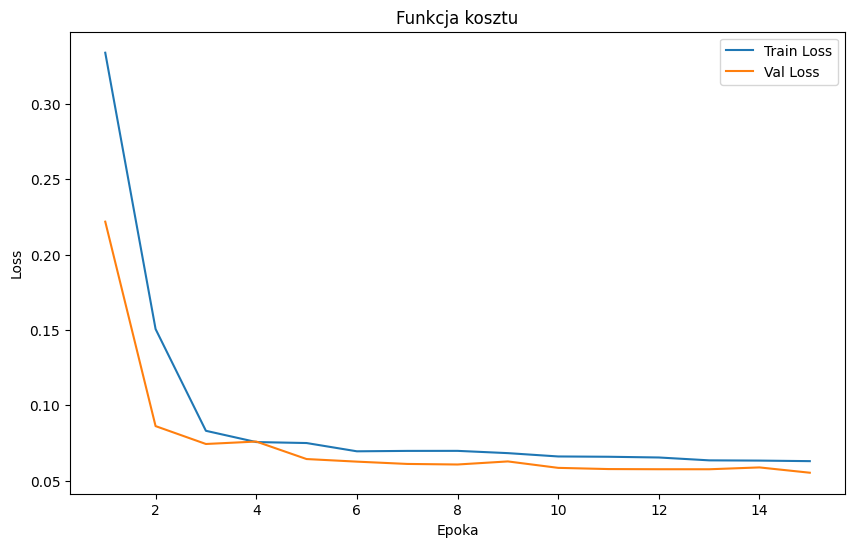

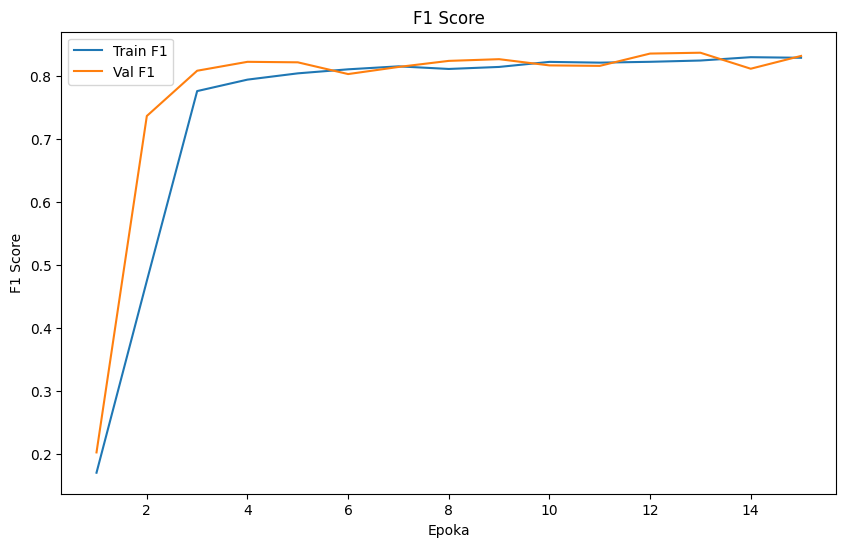

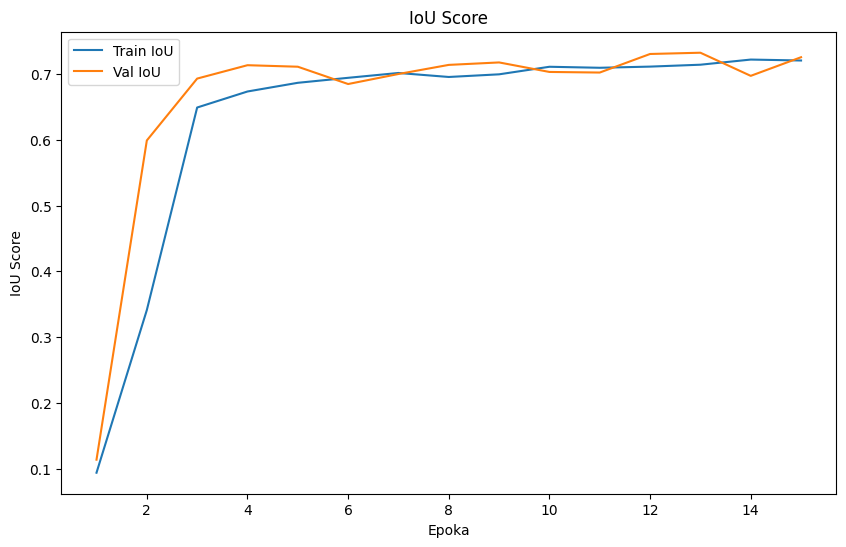

In [ ]:
# Rysowanie wykresów
epochs = range(1, num_epochs + 1)
train_f1_scores_numpy = torch.tensor(train_f1_scores).numpy()
val_f1_scores_numpy = torch.tensor(val_f1_scores).numpy()


train_iou_scores_numpy = torch.tensor(train_iou_scores).numpy()
val_iou_scores_numpy = torch.tensor(val_iou_scores).numpy()


# Funkcja kosztu
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Val Loss')
plt.xlabel('Epoka')
plt.ylabel('Loss')
plt.title('Funkcja kosztu')
plt.legend()

# F1 score
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_f1_scores_numpy, label='Train F1')
plt.plot(epochs, val_f1_scores_numpy, label='Val F1')
plt.xlabel('Epoka')
plt.ylabel('F1 Score')
plt.title('F1 Score')
plt.legend()

# IoU score
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_iou_scores_numpy, label='Train IoU')
plt.plot(epochs, val_iou_scores_numpy, label='Val IoU')
plt.xlabel('Epoka')
plt.ylabel('IoU Score')
plt.title('IoU Score')
plt.legend()

# Pokaż wykresy
plt.show()


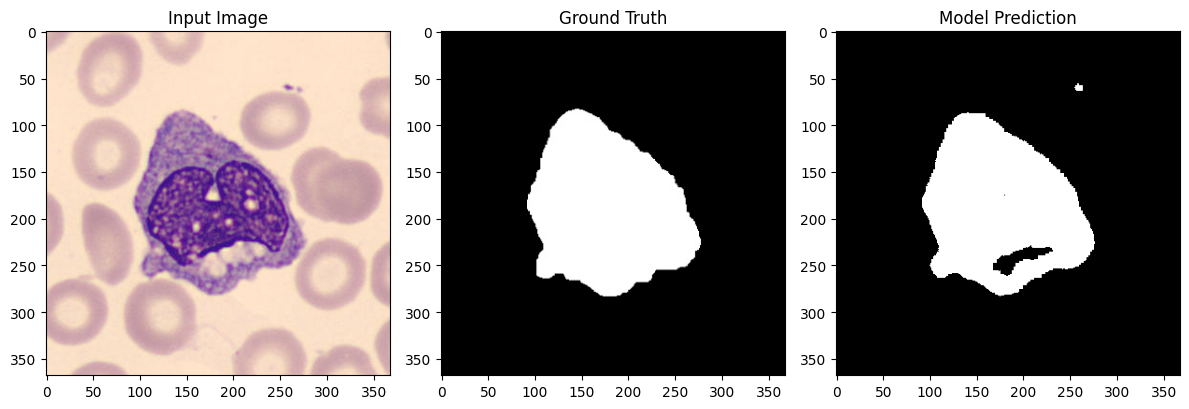

In [ ]:
# ======== Wizualizacja wyników ========
# Przykład predykcji na jednym przykładzie
sample_input = val_images[0:1]
with torch.no_grad():
    model_u.eval()
    prediction = torch.round(model_u(sample_input))

# Wyświetlanie przykładu
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(sample_input[0].permute(1, 2, 0).numpy())  # RGB obraz
axes[0].set_title('Input Image')

axes[1].imshow(val_masks[0, 0].numpy(), cmap='gray')  # Ground Truth
axes[1].set_title('Ground Truth')

axes[2].imshow(prediction[0, 0].numpy(), cmap='gray')  # Predykcja modelu
axes[2].set_title('Model Prediction')

plt.tight_layout()
plt.savefig('results7.png', dpi=300, bbox_inches='tight')
plt.show()



=== Wyniki na zbiorze testowym ====
Test Loss: 0.3297, Test F1: 0.0065, Test IoU: 0.0033


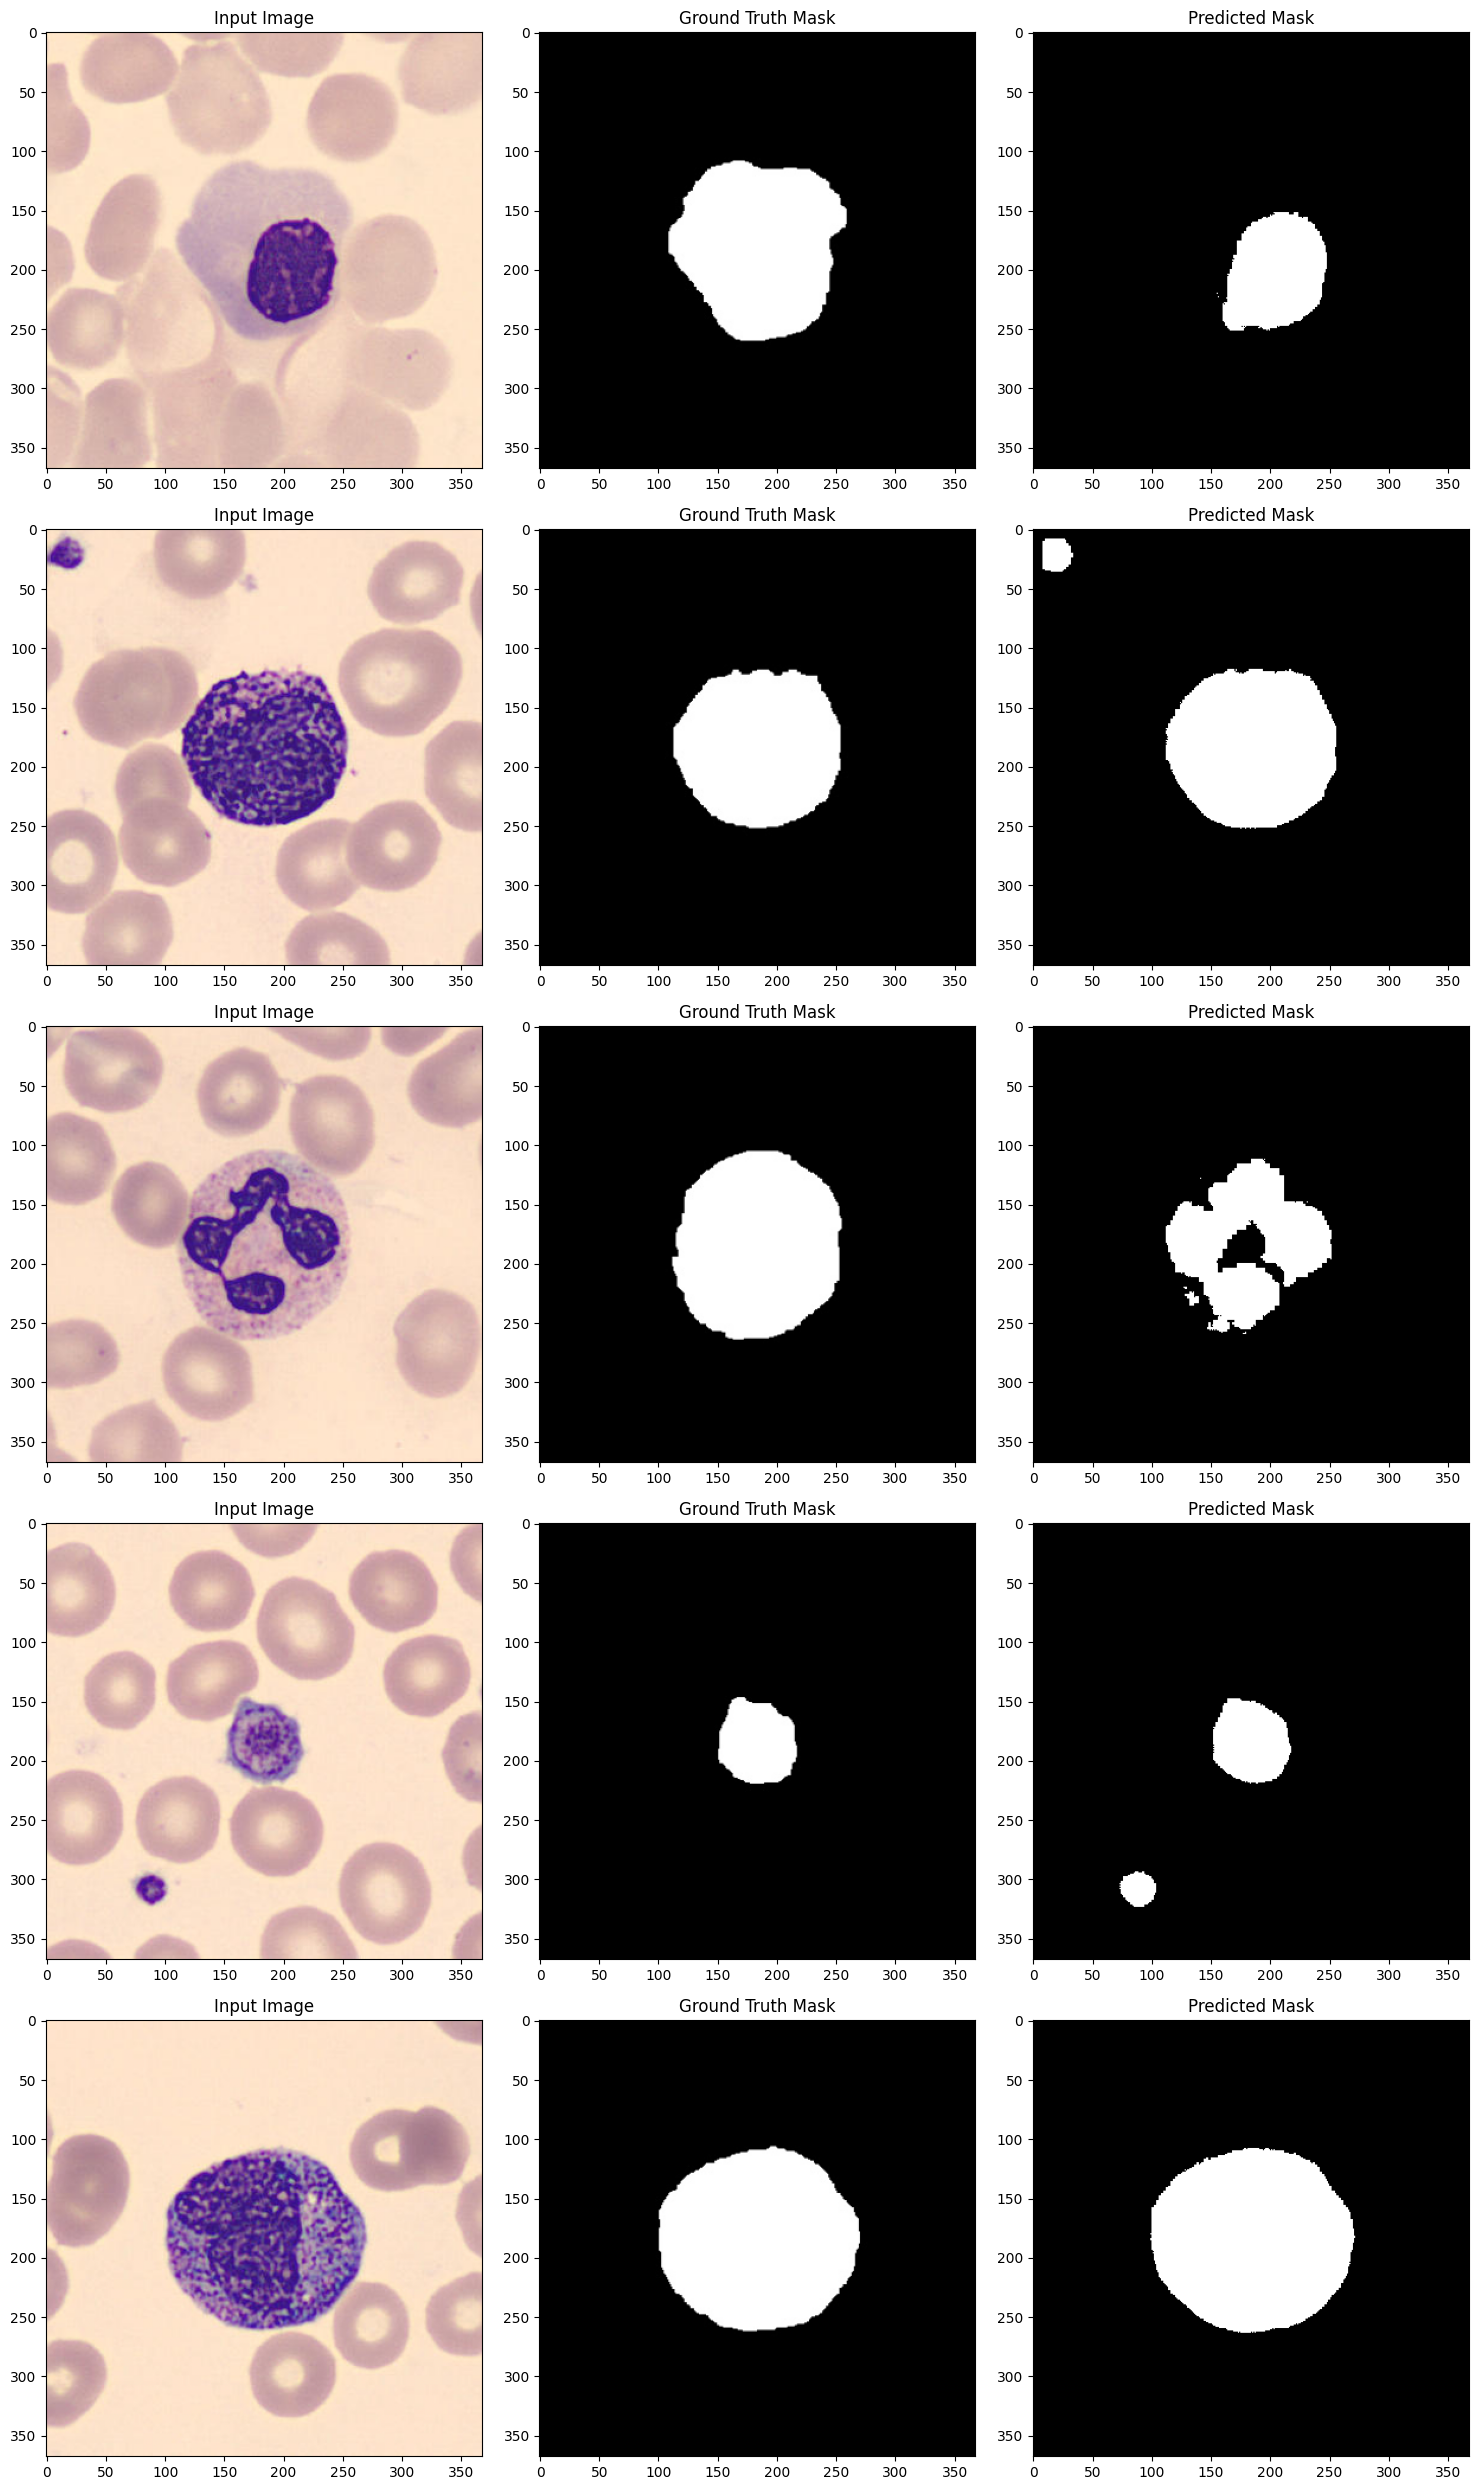

In [ ]:
# ======== Ewaluacja na zbiorze testowym ========
# Normalizacja masek
test_masks_normalized = np.array(test_masks) / 255.0

# Normalizacja obrazów testowych
test_images = np.array([np.array(img) for img in test_images]).astype(np.float32) / 255.0

# Dodanie kanału do masek testowych
test_masks_normalized = np.expand_dims(test_masks_normalized, axis=1)  # (N, 1, H, W)

# Transpozycja obrazów testowych do formatu (N, C, H, W)
test_images = np.transpose(test_images, (0, 3, 1, 2))  # (N, 3, H, W)

# Konwersja danych do tensorów
test_images = torch.tensor(test_images, dtype=torch.float32)
test_masks_normalized = torch.tensor(test_masks_normalized, dtype=torch.float32)

# Tworzenie datasetu dla danych testowych
test_dataset = torch.utils.data.TensorDataset(test_images, test_masks_normalized)

# Tworzenie DataLoadera dla testowego zbioru
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# ======== Ocena na zbiorze testowym ========
model_u.eval()
test_loss, test_f1, test_iou = 0.0, 0.0, 0.0
predictions, ground_truths, inputs_list = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model_u(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item()
        test_f1 += f1_score(outputs, labels)
        test_iou += iou_score(outputs, labels)

        predictions.append(outputs)
        ground_truths.append(labels)
        inputs_list.append(inputs)

# Obliczanie średnich wyników testowych
test_loss /= len(test_loader)
test_f1 /= len(test_loader)
test_iou /= len(test_loader)

print("\n=== Wyniki na zbiorze testowym ====")
print(f"Test Loss: {test_loss:.4f}, Test F1: {test_f1:.4f}, Test IoU: {test_iou:.4f}")

# Wizualizacja wyników
num_samples = 5  # Liczba przykładów do wizualizacji
fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))

for i in range(num_samples):
    sample_input = inputs_list[0][i].cpu()
    sample_truth = ground_truths[0][i].cpu()
    sample_prediction = torch.round(predictions[0][i].cpu())

    axes[i, 0].imshow(sample_input.permute(1, 2, 0).numpy())
    axes[i, 0].set_title('Input Image')

    axes[i, 1].imshow(sample_truth[0].numpy(), cmap='gray')
    axes[i, 1].set_title('Ground Truth Mask')

    axes[i, 2].imshow(sample_prediction[0].numpy(), cmap='gray')
    axes[i, 2].set_title('Predicted Mask')

plt.tight_layout()
plt.savefig('test_results.png', dpi=300, bbox_inches='tight')
plt.show()
